# 🔬 Перевірка гіпотез і статистичні тести в SciPy

**Заняття: основи перевірки гіпотез · вступ до `scipy.stats` · статистичні тести**

Тривалість: **90 хвилин** · Інструменти: `numpy`, `pandas`, `matplotlib`, `scipy`

| # | Тема | Час |
|---|---|---|
| 0 | Вступ: різниця чи шум? | 3 хв |
| | **Частина 1. Основи перевірки гіпотез** | |
| 1 | Нульова й альтернативна гіпотези, помилки | 8 хв |
| 2 | Рівень значущості та p-value | 12 хв |
| 3 | Довірчий інтервал | 8 хв |
| 4 | A/B-тест як приклад | 7 хв |
| | **Частина 2. Вступ до SciPy** | |
| 5 | Структура SciPy | 3 хв |
| 6 | Розподіли в `scipy.stats` | 8 хв |
| 7 | Описова статистика | 4 хв |
| 8 | Довірчі інтервали в SciPy | 5 хв |
| | **Частина 3. Статистичні тести** | |
| 9 | t-тест | 12 хв |
| 10 | Критерій хі-квадрат | 7 хв |
| 11 | Кореляція з p-value | 5 хв |
| 12 | Як інтерпретувати результати | 6 хв |
| 13 | Підсумок: який тест обрати | 2 хв |
| ✍️ | Перевірте себе (домашнє завдання) | — |

> 💡 Ноутбук можна відкрити в **Google Colab**: *File → Upload notebook*. Усі дані генеруються всередині ноутбука.

---
## 0. Вступ (⏱ 3 хв)

Ми змінили кнопку «Купити» на сайті. Конверсія зросла з 10.0% до 12.2%. **Нова кнопка краща?**

Можливо. А можливо, нам просто пощастило: навіть якщо нічого не міняти, конверсія щодня трохи «стрибає» (ми бачили це в законі великих чисел).

**Перевірка гіпотез** — це спосіб відповісти на питання **«це справжня різниця чи випадковий шум?»** з контрольованим ризиком помилки.

Сьогоднішній план:
1. Логіка перевірки гіпотез: H₀, H₁, p-value, довірчі інтервали.
2. Інструмент: бібліотека **SciPy**, модуль `scipy.stats`.
3. Готові тести: t-тест, хі-квадрат, кореляція — і як правильно читати їхні результати.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.float_format', '{:.4f}'.format)

rng = np.random.default_rng(11)

---
# Частина 1. Основи перевірки гіпотез

## 1. Нульова й альтернативна гіпотези (⏱ 8 хв)

**Аналогія — суд.** Діє презумпція невинуватості: людина вважається **невинною**, доки докази не переконають у протилежному. Суд не «доводить невинуватість» — він лише вирішує, чи достатньо доказів провини.

| | У суді | У статистиці |
|---|---|---|
| Початкове припущення | обвинувачений невинний | **H₀ — нульова гіпотеза**: «нічого не змінилось», «ефекту немає», «різниці немає» |
| Те, що хочемо показати | обвинувачений винний | **H₁ — альтернативна гіпотеза**: «ефект є», «різниця є» |
| Докази | свідчення, експертизи | **дані** |
| Рішення | «винний» або «вину не доведено» | «**відхиляємо H₀**» або «**не відхиляємо H₀**» |

> ⚠️ **«Не відхиляємо H₀» ≠ «H₀ доведена».** Як і «вину не доведено» ≠ «доведено невинуватість». Можливо, просто замало даних.

### Приклади

| Питання | H₀ | H₁ |
|---|---|---|
| Нова кнопка підвищує конверсію? | конверсії однакові | конверсії різні |
| Кур'єри доставляють за обіцяні 30 хв? | середній час = 30 хв | середній час ≠ 30 хв |
| Кубик чесний? | усі грані випадають однаково часто | частоти різні |
| Реклама пов'язана з продажами? | кореляція = 0 | кореляція ≠ 0 |

**Двостороння** H₁: «різниця є» (у будь-який бік) — ≠. **Одностороння**: «нова версія **краща**» — > або <. Якщо немає вагомої причини, використовуйте двосторонню.

### Дві можливі помилки

| | H₀ насправді правдива | H₀ насправді хибна |
|---|---|---|
| **Відхилили H₀** | ❌ **Помилка I роду** (хибна тривога). Ймовірність = α | ✅ правильно |
| **Не відхилили H₀** | ✅ правильно | ❌ **Помилка II роду** (пропустили ефект). Ймовірність = β |

**Мовою бізнесу:** помилка I роду — запустили нову кнопку, яка насправді не краща. Помилка II роду — відмовились від кнопки, яка насправді була кращою.

---
## 2. Рівень значущості та p-value (⏱ 12 хв)

**Рівень значущості α** — це межа ризику помилки I роду, яку ми **заздалегідь** погоджуємося прийняти. Найчастіше α = 0.05 (5%).

**p-value** — це ймовірність отримати такі самі **або ще більш екстремальні** дані, **якщо H₀ правдива**.

Простими словами: «Якби насправді ефекту не було, наскільки дивними здавалися б наші дані?»

| p-value | Що означає | Рішення при α = 0.05 |
|---|---|---|
| маленький (≤ 0.05) | такі дані **малоймовірні**, якщо H₀ правдива | **відхиляємо H₀** |
| великий (> 0.05) | такі дані цілком **звичайні** за H₀ | **не відхиляємо H₀** |

### Приклад: чи чесна монетка?

Підкинули монетку 100 разів — **60 орлів**. H₀: монетка чесна (p = 0.5). Порахуємо p-value **симуляцією**: 100 000 разів «підкинемо» чесну монетку по 100 разів і подивимось, як часто виходить результат, що відхиляється від 50 так само сильно або сильніше (≥ 60 або ≤ 40).

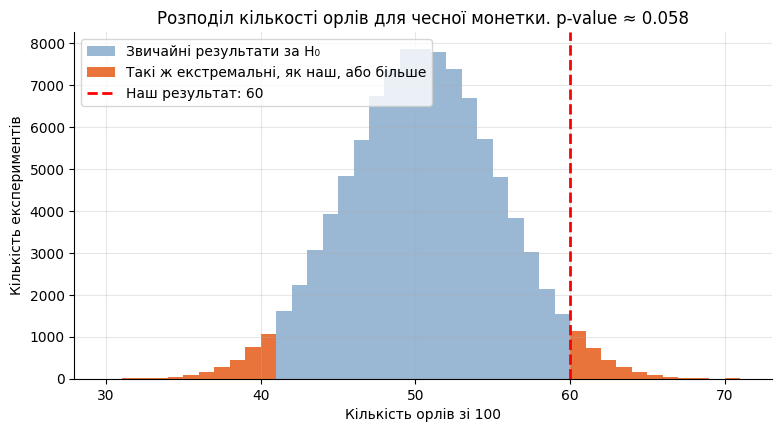

In [2]:
n_flips, observed = 100, 60

# 100 000 експериментів з ЧЕСНОЮ монеткою (тобто за умови, що H₀ правдива)
sim_heads = rng.binomial(n_flips, 0.5, size=100_000)

extreme = np.abs(sim_heads - 50) >= abs(observed - 50)   # так само далеко від 50 або далі
p_sim = extreme.mean()

plt.hist(sim_heads[~extreme], bins=range(30, 72), color='#9ab7d3', label='Звичайні результати за H₀')
plt.hist(sim_heads[extreme], bins=range(30, 72), color='#E8743B', label='Такі ж екстремальні, як наш, або більше')
plt.axvline(observed, color='red', linestyle='--', linewidth=2, label=f'Наш результат: {observed}')
plt.title(f'Розподіл кількості орлів для чесної монетки. p-value ≈ {p_sim:.3f}')
plt.xlabel('Кількість орлів зі 100')
plt.ylabel('Кількість експериментів')
plt.legend()
plt.show()

In [3]:
# Те саме точним тестом зі SciPy
res = stats.binomtest(60, n=100, p=0.5)
print(f'p-value (симуляція): {p_sim:.4f}')
print(f'p-value (binomtest): {res.pvalue:.4f}')
print('Рішення при α = 0.05:', 'відхиляємо H₀' if res.pvalue <= 0.05 else 'не відхиляємо H₀')

p-value (симуляція): 0.0577
p-value (binomtest): 0.0569
Рішення при α = 0.05: не відхиляємо H₀


In [4]:
# А якщо 65 орлів?
res65 = stats.binomtest(65, n=100, p=0.5)
print(f'65 орлів зі 100: p-value = {res65.pvalue:.4f} →',
      'відхиляємо H₀' if res65.pvalue <= 0.05 else 'не відхиляємо H₀')

65 орлів зі 100: p-value = 0.0035 → відхиляємо H₀


**60 орлів:** p ≈ 0.057 — трохи більше за 0.05. Такий результат для чесної монетки трапляється приблизно в 6 випадках зі 100. Доказів, що монетка нечесна, **недостатньо**.

**65 орлів:** p ≈ 0.004 — для чесної монетки це трапляється рідше ніж 1 раз на 200. **Відхиляємо H₀**: монетка, найімовірніше, нечесна.

### ⚠️ Чим p-value НЕ є

| Поширена помилка | Як правильно |
|---|---|
| «p = 0.03 — ймовірність, що H₀ правдива, 3%» | p-value рахують, **припускаючи**, що H₀ правдива. Це ймовірність **даних**, а не гіпотези |
| «p = 0.001 — ефект дуже великий» | p-value не міряє розмір ефекту. На величезних даних і крихітний ефект дасть мізерний p |
| «p = 0.20 — отже, ефекту немає» | Лише «доказів недостатньо». Можливо, замало даних |
| «p = 0.049 — успіх, p = 0.051 — провал» | Межа 0.05 — домовленість, а не закон природи. Дивіться на p-value разом з розміром ефекту |

---
## 3. Довірчий інтервал (⏱ 8 хв)

Ми порахували середнє на вибірці. Але справжнє середнє μ невідоме. **Довірчий інтервал (ДІ)** дає **діапазон правдоподібних значень** μ.

З ЦГТ ми знаємо, що середнє вибірки розподілене приблизно нормально з розкидом SE = s / √n. Тому 95% ДІ:

$$\bar{x} \pm 1.96 \cdot SE$$

(Для малих вибірок замість 1.96 беруть трохи більше число з t-розподілу — SciPy зробить це сам, розділ 8.)

### Як правильно розуміти 95% ДІ

Якщо повторити дослідження **багато разів** і щоразу будувати 95% ДІ, то **приблизно 95% інтервалів** «накриють» справжнє μ. Перевіримо симуляцією: справжнє μ = 50, беремо 100 вибірок по 30.

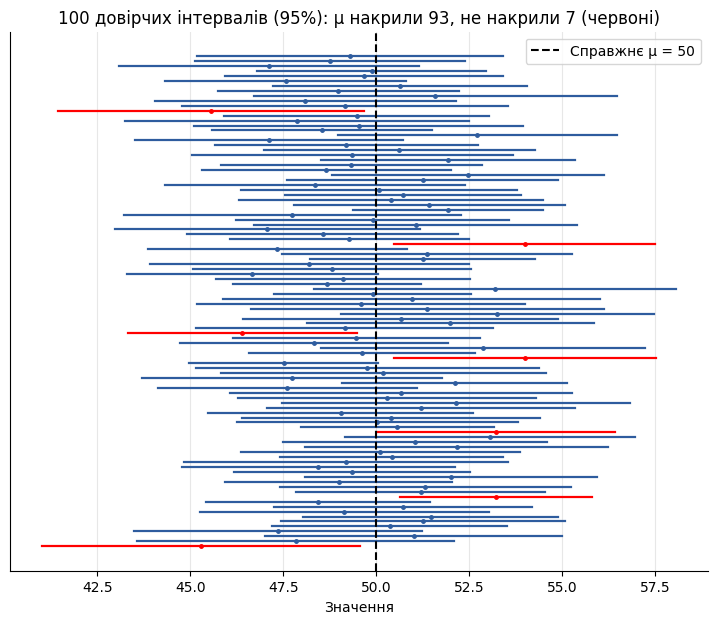

In [5]:
mu_true, sigma_true, n = 50, 10, 30
fig, ax = plt.subplots(figsize=(9, 7))
covered = 0
for i in range(100):
    sample = rng.normal(mu_true, sigma_true, n)
    low, high = stats.t.interval(0.95, df=n - 1, loc=sample.mean(), scale=stats.sem(sample))
    hit = low <= mu_true <= high
    covered += hit
    ax.plot([low, high], [i, i], color='#2E5C9E' if hit else 'red', linewidth=1.6)
    ax.plot(sample.mean(), i, 'o', color='#2E5C9E' if hit else 'red', markersize=2.5)
ax.axvline(mu_true, color='black', linestyle='--', label='Справжнє μ = 50')
ax.set_title(f'100 довірчих інтервалів (95%): μ накрили {covered}, не накрили {100 - covered} (червоні)')
ax.set_xlabel('Значення')
ax.set_yticks([])
ax.legend()
plt.show()

**Зв'язок ДІ і перевірки гіпотез.** Якщо 95% ДІ для різниці між групами **не містить 0**, то двосторонній тест при α = 0.05 відхилить H₀ «різниці немає». ДІ корисніший за голий p-value: він показує ще й **розмір** ефекту.

**Що впливає на ширину ДІ:**
- більша вибірка → вужчий інтервал (SE = s / √n);
- більший розкид даних → ширший;
- вищий рівень довіри (99% замість 95%) → ширший.

---
## 4. A/B-тест як приклад (⏱ 7 хв)

Магазин випадково показує відвідувачам стару (A) або нову (B) кнопку «Купити».

| Група | Відвідувачів | Купили | Конверсія |
|---|---|---|---|
| A (стара) | 2000 | 200 | 10.0% |
| B (нова) | 2000 | 245 | 12.25% |

**H₀:** конверсії однакові ($p_A = p_B$). **H₁:** конверсії різні. **α = 0.05.**

Використаємо **z-тест для двох часток**:

$$z = \frac{\hat{p}_B - \hat{p}_A}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_A} + \frac{1}{n_B}\right)}}$$

де $\hat{p}$ — спільна конверсія обох груп разом. Далі p-value рахуємо через нормальний розподіл.

In [6]:
n_a, conv_a = 2000, 200
n_b, conv_b = 2000, 245

p_a, p_b = conv_a / n_a, conv_b / n_b
diff = p_b - p_a

p_pool = (conv_a + conv_b) / (n_a + n_b)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
z = diff / se_pool
p_value = 2 * stats.norm.sf(abs(z))          # двосторонній: обидва «хвости»

# 95% довірчий інтервал для різниці (SE без об'єднання груп)
se_diff = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
ci_low, ci_high = diff - 1.96 * se_diff, diff + 1.96 * se_diff

print(f'Конверсія A: {p_a:.2%} | B: {p_b:.2%} | різниця: {diff:+.2%}')
print(f'z = {z:.2f}, p-value = {p_value:.4f}')
print(f'95% ДІ для різниці: від {ci_low:+.2%} до {ci_high:+.2%}')
print('Рішення:', 'відхиляємо H₀' if p_value <= 0.05 else 'не відхиляємо H₀')

Конверсія A: 10.00% | B: 12.25% | різниця: +2.25%
z = 2.26, p-value = 0.0236
95% ДІ для різниці: від +0.30% до +4.20%
Рішення: відхиляємо H₀


**Висновок:** p-value ≈ 0.02 < 0.05, тому відхиляємо H₀: різниця, найімовірніше, не випадкова. ДІ від ~+0.3 до ~+4.2 п.п. не містить 0, і **вся** його частина додатна: нова кнопка краща, хоча точний розмір покращення ще досить невизначений.

### ⚠️ Правила чесного A/B-тесту
1. **Випадковий розподіл** користувачів на групи.
2. **Розмір вибірки і тривалість визначають заздалегідь.** Не можна «підглядати» щодня і зупинити тест, щойно p < 0.05: так хибні «перемоги» трапляються набагато частіше за 5%.
3. **Одна головна метрика** визначається до старту.
4. Рішення приймають за **p-value + розміром ефекту + ДІ**, а не лише за p.

---
# Частина 2. Вступ до SciPy

## 5. Структура SciPy (⏱ 3 хв)

**SciPy** (*Scientific Python*) — бібліотека наукових обчислень, побудована поверх `numpy`. Складається з модулів:

| Модуль | Для чого |
|---|---|
| **`scipy.stats`** | **розподіли, описова статистика, статистичні тести** ← сьогодні працюємо з ним |
| `scipy.optimize` | пошук мінімуму/максимуму, підбір параметрів |
| `scipy.linalg` | лінійна алгебра (матриці) |
| `scipy.interpolate` | інтерполяція |
| `scipy.signal` | обробка сигналів |
| `scipy.integrate` | інтегрування |

Стандартний імпорт: `from scipy import stats`.

**Що є в `scipy.stats`:**
- **розподіли** — `stats.norm`, `stats.binom`, `stats.poisson`, `stats.t`, `stats.chi2`… (понад 100);
- **описова статистика** — `stats.describe`, `stats.sem`, `stats.iqr`, `stats.skew`, `stats.zscore`…;
- **тести** — `stats.ttest_ind`, `stats.chi2_contingency`, `stats.pearsonr`, `stats.binomtest`…

In [7]:
import scipy
print('Версія SciPy:', scipy.__version__)

# Скільки функцій і розподілів у scipy.stats
print('Об\'єктів у scipy.stats:', len([x for x in dir(stats) if not x.startswith('_')]))

Версія SciPy: 1.16.3
Об'єктів у scipy.stats: 313


---
## 6. Розподіли в `scipy.stats` (⏱ 8 хв)

Кожен розподіл — це **об'єкт** з однаковим набором методів:

| Метод | Що повертає | Приклад питання |
|---|---|---|
| `.pdf(x)` / `.pmf(k)` | щільність / ймовірність точного значення | «Яка ймовірність рівно 3 покупців?» (pmf) |
| `.cdf(x)` | P(X ≤ x) | «Яка частка зросту ≤ 180 см?» |
| `.sf(x)` | P(X > x) = 1 − cdf | «Яка частка вищих за 190 см?» |
| `.ppf(q)` | значення, нижче якого частка q (зворотне до cdf) | «Який зріст відділяє 5% найвищих?» |
| `.rvs(size)` | випадкові числа з цього розподілу | згенерувати дані |
| `.mean()`, `.std()` | середнє, стандартне відхилення | |

> `pmf` — для **дискретних** розподілів (біноміальний, Пуассона), `pdf` — для **неперервних** (нормальний, t).

In [8]:
# Нормальний розподіл: зріст, μ = 176, σ = 7
height = stats.norm(loc=176, scale=7)

print(f'P(зріст ≤ 180) = {height.cdf(180):.3f}')
print(f'P(зріст > 190) = {height.sf(190):.3f}')
print(f'95-й перцентиль: {height.ppf(0.95):.1f} см')
print(f'5 випадкових значень: {height.rvs(size=5, random_state=1).round(1)}')

P(зріст ≤ 180) = 0.716
P(зріст > 190) = 0.023
95-й перцентиль: 187.5 см
5 випадкових значень: [187.4 171.7 172.3 168.5 182.1]


In [9]:
# Критичне значення 1.96 для 95% ДІ — звідки воно?
print('stats.norm.ppf(0.975) =', round(stats.norm.ppf(0.975), 3))
# 2.5% праворуч + 2.5% ліворуч = 5% поза інтервалом → 95% всередині

stats.norm.ppf(0.975) = 1.96


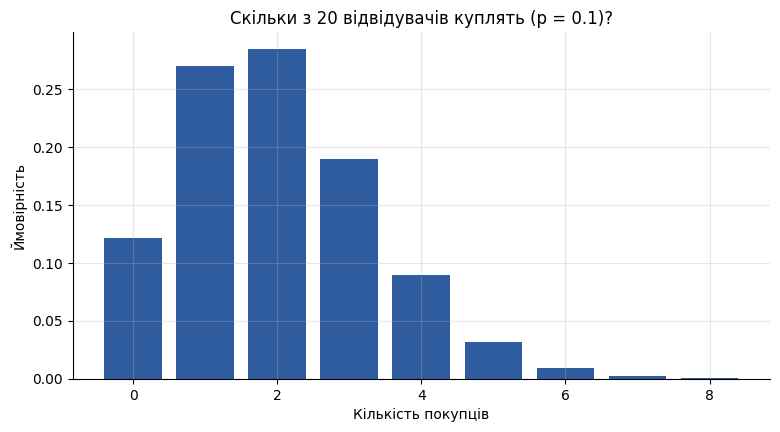

P(рівно 2) = 0.285
P(хоча б 3) = P(X > 2) = 0.323


In [10]:
# Біноміальний розподіл: 20 відвідувачів, кожен купує з ймовірністю 0.1
buyers = stats.binom(n=20, p=0.1)
k = np.arange(0, 9)

plt.bar(k, buyers.pmf(k), color='#2E5C9E')
plt.title('Скільки з 20 відвідувачів куплять (p = 0.1)?')
plt.xlabel('Кількість покупців')
plt.ylabel('Ймовірність')
plt.show()

print(f'P(рівно 2) = {buyers.pmf(2):.3f}')
print(f'P(хоча б 3) = P(X > 2) = {buyers.sf(2):.3f}')

In [11]:
# Розподіл Пуассона: кількість подій за інтервал. У середньому 4 дзвінки на годину
calls = stats.poisson(mu=4)
print(f'P(рівно 6 дзвінків) = {calls.pmf(6):.3f}')
print(f'P(більше 8 дзвінків) = {calls.sf(8):.4f}')

P(рівно 6 дзвінків) = 0.104
P(більше 8 дзвінків) = 0.0214


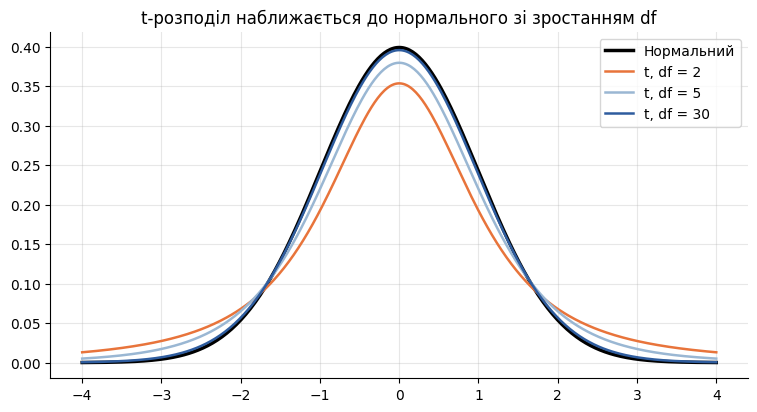

df =    2: критичне значення для 95% = 4.303
df =    5: критичне значення для 95% = 2.571
df =   30: критичне значення для 95% = 2.042
df = 1000: критичне значення для 95% = 1.962


In [12]:
# t-розподіл — «товстіші хвости», ніж у нормального, коли вибірка мала
xs = np.linspace(-4, 4, 400)
plt.plot(xs, stats.norm.pdf(xs), color='black', linewidth=2.5, label='Нормальний')
for df_, c in [(2, '#E8743B'), (5, '#9ab7d3'), (30, '#2E5C9E')]:
    plt.plot(xs, stats.t.pdf(xs, df=df_), color=c, linewidth=1.8, label=f't, df = {df_}')
plt.title('t-розподіл наближається до нормального зі зростанням df')
plt.legend()
plt.show()

for df_ in [2, 5, 30, 1000]:
    print(f'df = {df_:>4}: критичне значення для 95% = {stats.t.ppf(0.975, df=df_):.3f}')

**df** (*degrees of freedom*, ступені свободи) для одновибіркового t-тесту — це n − 1. На маленьких вибірках t-розподіл ширший, і критичне значення більше за 1.96: ми чесно визнаємо більшу невизначеність.

---
## 7. Описова статистика в SciPy (⏱ 4 хв)

| Функція | Що рахує |
|---|---|
| `stats.describe(x)` | n, min/max, середнє, дисперсію, асиметрію, ексцес — усе разом |
| `stats.sem(x)` | **стандартну похибку середнього** SE = s / √n |
| `stats.iqr(x)` | міжквартильний розмах |
| `stats.skew(x)`, `stats.kurtosis(x)` | асиметрію, ексцес |
| `stats.zscore(x)` | z-оцінки всіх значень |
| `stats.mode(x)` | моду |

In [13]:
# Час доставки 40 замовлень, хв
delivery = np.round(rng.normal(33, 6, 40), 1)

d = stats.describe(delivery)          # повертає одразу кілька показників
print(f'n = {d.nobs} | min = {d.minmax[0]} | max = {d.minmax[1]}')
print(f'Середнє: {d.mean:.2f} | Дисперсія: {d.variance:.2f}')
print(f'Асиметрія: {d.skewness:.2f} | Ексцес: {d.kurtosis:.2f}')
print(f'SE (stats.sem): {stats.sem(delivery):.3f}   (перевірка: {delivery.std(ddof=1) / np.sqrt(len(delivery)):.3f})')
print(f'IQR: {stats.iqr(delivery):.2f}')
print(f'z-оцінки перших 5: {stats.zscore(delivery)[:5].round(2)}')

n = 40 | min = 21.4 | max = 44.1
Середнє: 34.24 | Дисперсія: 28.12
Асиметрія: -0.17 | Ексцес: -0.40
SE (stats.sem): 0.838   (перевірка: 0.838)
IQR: 7.25
z-оцінки перших 5: [-0.45 -0.75 -1.33 -0.62 -0.6 ]


---
## 8. Довірчі інтервали в SciPy (⏱ 5 хв)

**ДІ для середнього** (через t-розподіл):

```python
stats.t.interval(0.95, df=n - 1, loc=середнє, scale=SE)
```

**ДІ для частки** (через нормальне наближення, коли n великий):

```python
stats.norm.interval(0.95, loc=p̂, scale=√(p̂(1 − p̂) / n))
```

**ДІ для будь-чого (медіани, p90…)** — **бутстреп**: багато разів беремо з даних вибірку «з поверненням», рахуємо статистику, і беремо 2.5-й і 97.5-й перцентилі результатів.

In [14]:
n = len(delivery)
mean, se = delivery.mean(), stats.sem(delivery)

for level in [0.90, 0.95, 0.99]:
    low, high = stats.t.interval(level, df=n - 1, loc=mean, scale=se)
    print(f'{level:.0%} ДІ для середнього часу доставки: {low:.2f} … {high:.2f} хв  (ширина {high - low:.2f})')

90% ДІ для середнього часу доставки: 32.83 … 35.65 хв  (ширина 2.83)
95% ДІ для середнього часу доставки: 32.54 … 35.94 хв  (ширина 3.39)
99% ДІ для середнього часу доставки: 31.97 … 36.51 хв  (ширина 4.54)


In [15]:
# Вручну: x̄ ± t* · SE
t_star = stats.t.ppf(0.975, df=n - 1)
print(f't* = {t_star:.3f} → {mean - t_star * se:.2f} … {mean + t_star * se:.2f} хв')

t* = 2.023 → 32.54 … 35.94 хв


In [16]:
# ДІ для частки: конверсія групи B з A/B-тесту
se_b = np.sqrt(p_b * (1 - p_b) / n_b)
low, high = stats.norm.interval(0.95, loc=p_b, scale=se_b)
print(f'Конверсія B: {p_b:.2%}, 95% ДІ: {low:.2%} … {high:.2%}')

Конверсія B: 12.25%, 95% ДІ: 10.81% … 13.69%


Медіана: 34.2 хв, 95% бутстреп-ДІ: 32.5 … 36.0 хв


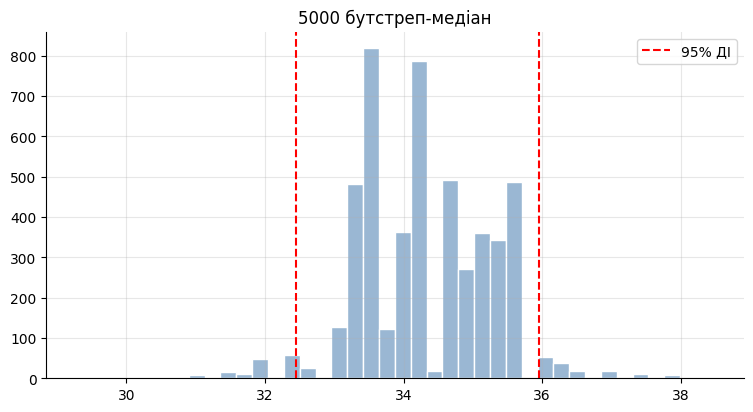

In [17]:
# Бутстреп-ДІ для медіани
boot = np.array([np.median(rng.choice(delivery, size=n, replace=True)) for _ in range(5000)])
low, high = np.percentile(boot, [2.5, 97.5])
print(f'Медіана: {np.median(delivery):.1f} хв, 95% бутстреп-ДІ: {low:.1f} … {high:.1f} хв')

plt.hist(boot, bins=40, color='#9ab7d3', edgecolor='white')
plt.axvline(low, color='red', linestyle='--'); plt.axvline(high, color='red', linestyle='--', label='95% ДІ')
plt.title('5000 бутстреп-медіан')
plt.legend()
plt.show()

---
# Частина 3. Статистичні тести

Усі тести в SciPy повертають щонайменше два числа: **статистику** тесту і **p-value**. Порядок дій завжди однаковий:

1. Сформулювати H₀ і H₁. Обрати α (зазвичай 0.05) — **до** того, як дивитися на дані.
2. Обрати тест, що відповідає типу даних і питанню.
3. Запустити тест, отримати p-value.
4. p ≤ α → відхиляємо H₀; p > α → не відхиляємо.
5. **Обов'язково** подивитися на розмір ефекту і ДІ.

## 9. t-тест (⏱ 12 хв)

t-тест порівнює **середні**.

| Тест | Питання | Функція |
|---|---|---|
| **Одновибірковий** | середнє однієї групи = заданому числу? | `stats.ttest_1samp(x, popmean)` |
| **Двовибірковий незалежний** | середні двох **різних** груп однакові? | `stats.ttest_ind(a, b, equal_var=False)` |
| **Парний** | середнє змінилось **у тих самих** об'єктів «до» і «після»? | `stats.ttest_rel(before, after)` |

> 💡 У `ttest_ind` ставте `equal_var=False` (**t-тест Велча**). Він не вимагає, щоб розкид у групах був однаковий, і майже нічого не втрачає, якщо розкиди таки однакові.

In [18]:
# 1) Одновибірковий: сервіс обіцяє доставку в середньому за 30 хв. Чи це так?
# H₀: μ = 30;  H₁: μ ≠ 30
res = stats.ttest_1samp(delivery, popmean=30)
print(f'Середнє у вибірці: {delivery.mean():.2f} хв')
print(f't = {res.statistic:.2f}, p-value = {res.pvalue:.6f}')

# t-статистика — це «на скільки SE середнє відрізняється від 30»
print(f'Перевірка вручну: t = (x̄ − 30) / SE = {(delivery.mean() - 30) / stats.sem(delivery):.2f}')

Середнє у вибірці: 34.24 хв
t = 5.06, p-value = 0.000010
Перевірка вручну: t = (x̄ − 30) / SE = 5.06


p-value дуже малий: якби справжнє середнє було 30 хв, таке середнє у вибірці з 40 замовлень було б майже неможливим. **Відхиляємо H₀**: доставка в середньому повільніша, ніж обіцяно (95% ДІ з розділу 8 весь лежить вище 30).

Середній чек A: 507 грн | B: 564 грн | різниця: +57 грн
t = -3.31, p-value = 0.0013


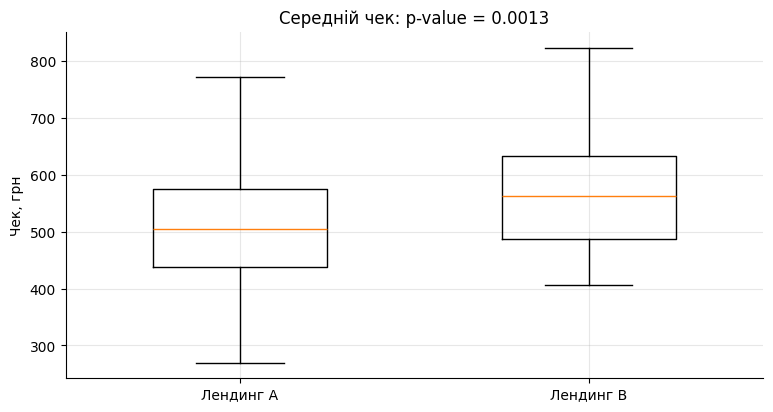

In [19]:
# 2) Незалежні групи: середній чек на двох версіях лендингу
check_a = np.round(rng.normal(520, 90, 60))
check_b = np.round(rng.normal(565, 95, 60))

res = stats.ttest_ind(check_a, check_b, equal_var=False)
print(f'Середній чек A: {check_a.mean():.0f} грн | B: {check_b.mean():.0f} грн | різниця: {check_b.mean() - check_a.mean():+.0f} грн')
print(f't = {res.statistic:.2f}, p-value = {res.pvalue:.4f}')

plt.boxplot([check_a, check_b], widths=0.5)
plt.xticks([1, 2], ['Лендинг A', 'Лендинг B'])
plt.title(f'Середній чек: p-value = {res.pvalue:.4f}')
plt.ylabel('Чек, грн')
plt.show()

In [20]:
# 3) Парний: продажі 12 менеджерів до і після тренінгу
before = np.array([42, 55, 38, 61, 47, 52, 44, 58, 39, 50, 46, 53])
after  = np.array([45, 58, 41, 62, 52, 53, 49, 60, 40, 55, 47, 58])

paired = stats.ttest_rel(before, after)
wrong = stats.ttest_ind(before, after, equal_var=False)

print(f'Середній приріст: {(after - before).mean():+.2f} угоди')
print(f'Парний t-тест (правильно):        p = {paired.pvalue:.5f}')
print(f'Незалежний t-тест (неправильно):  p = {wrong.pvalue:.4f}')

Середній приріст: +2.92 угоди
Парний t-тест (правильно):        p = 0.00011
Незалежний t-тест (неправильно):  p = 0.3413


**Чому парний тест «бачить» ефект, а незалежний — ні?** Менеджери дуже різні: хтось продає 40, хтось 60. Незалежний тест порівнює дві «хмари» і тоне в цій різниці між людьми. Парний тест дивиться на **приріст кожної людини**, а прирости майже в усіх додатні. Якщо дані «до/після» для тих самих об'єктів — завжди парний тест.

---
## 10. Критерій хі-квадрат (⏱ 7 хв)

Хі-квадрат працює з **категоріальними** даними — з **частотами** (кількостями).

| Тест | Питання | Функція |
|---|---|---|
| **Незалежність** (таблиця спряженості) | дві категоріальні ознаки пов'язані? Напр., пристрій і факт покупки | `stats.chi2_contingency(table)` |
| **Згода** | спостережувані частоти відповідають очікуваним? Напр., кубик чесний? | `stats.chisquare(observed, expected)` |

**Ідея:** порівнюємо **спостережувані** частоти з **очікуваними** (якби H₀ була правдивою):

$$\chi^2 = \sum \frac{(\text{спостережувана} - \text{очікувана})^2}{\text{очікувана}}$$

Що більша χ², то сильніше дані відрізняються від H₀, і то менший p-value.

> ⚠️ Умова: очікувані частоти в кожній клітинці бажано **≥ 5**.

In [21]:
# Незалежність: чи пов'язаний пристрій з покупкою?
table = pd.DataFrame({'Купив': [240, 165], 'Не купив': [2760, 1335]}, index=['Мобільний', 'Комп\'ютер'])
print(table)
print('\nКонверсія:', (table['Купив'] / table.sum(axis=1)).round(3).to_dict())

chi2, p, dof, expected = stats.chi2_contingency(table)
print(f'\nχ² = {chi2:.2f}, df = {dof}, p-value = {p:.5f}')
print('\nОчікувані частоти, якби пристрій НЕ впливав:')
print(pd.DataFrame(expected, index=table.index, columns=table.columns).to_string(float_format='%.1f'))

           Купив  Не купив
Мобільний    240      2760
Комп'ютер    165      1335

Конверсія: {'Мобільний': 0.08, "Комп'ютер": 0.11}

χ² = 10.63, df = 1, p-value = 0.00112

Очікувані частоти, якби пристрій НЕ впливав:
           Купив  Не купив
Мобільний  270.0    2730.0
Комп'ютер  135.0    1365.0


In [22]:
# Той самий A/B-тест з розділу 4 через хі-квадрат дає той самий p-value
ab_table = [[conv_a, n_a - conv_a], [conv_b, n_b - conv_b]]
chi2, p_chi, _, _ = stats.chi2_contingency(ab_table, correction=False)
print(f'z-тест: p = {p_value:.5f} | хі-квадрат: p = {p_chi:.5f}   (z² = {z**2:.3f}, χ² = {chi2:.3f})')

z-тест: p = 0.02365 | хі-квадрат: p = 0.02365   (z² = 5.120, χ² = 5.120)


In [23]:
# Згода: кубик підкинули 120 разів. Чесний?
observed_dice = np.array([25, 17, 15, 23, 24, 16])
expected_dice = np.full(6, 120 / 6)          # якщо кубик чесний: по 20 на кожну грань

res = stats.chisquare(observed_dice, expected_dice)
print(f'χ² = {res.statistic:.2f}, p-value = {res.pvalue:.3f}')

χ² = 5.00, p-value = 0.416


p ≈ 0.4: такі відхилення від «по 20» для чесного кубика — звичайна справа. **Не відхиляємо H₀**. Це не доводить, що кубик ідеально чесний, але й доказів проти немає.

---
## 11. Кореляція з p-value (⏱ 5 хв)

`stats.pearsonr(x, y)` і `stats.spearmanr(x, y)` повертають **коефіцієнт кореляції r** і **p-value**.

**H₀:** кореляції в генеральній сукупності немає (ρ = 0).

> ⚠️ **Значущість ≠ сила.** p-value залежить від розміру вибірки:
> - на **великій** вибірці навіть дуже слабка кореляція буде «значущою»;
> - на **малій** вибірці навіть помітна кореляція може бути «незначущою».
>
> Тому завжди дивіться **і на r, і на p**.

In [24]:
# Реклама і продажі за 15 тижнів
ad = rng.uniform(10, 50, 15)
sales = 100 + 3 * ad + rng.normal(0, 20, 15)

r, p = stats.pearsonr(ad, sales)
rho, p_s = stats.spearmanr(ad, sales)
print(f'Пірсон: r = {r:.2f}, p = {p:.5f}')
print(f'Спірмен: ρ = {rho:.2f}, p = {p_s:.5f}')

Пірсон: r = 0.90, p = 0.00001
Спірмен: ρ = 0.92, p = 0.00000


In [25]:
# Значущість залежить від n
x_small = rng.normal(0, 1, 10);  y_small = 0.5 * x_small + rng.normal(0, 1, 10)
x_big = rng.normal(0, 1, 5000);  y_big = 0.06 * x_big + rng.normal(0, 1, 5000)

r1, p1 = stats.pearsonr(x_small, y_small)
r2, p2 = stats.pearsonr(x_big, y_big)
print(f'n = 10:   r = {r1:.2f}, p = {p1:.3f}  → {"значуща" if p1 <= 0.05 else "незначуща"}')
print(f'n = 5000: r = {r2:.2f}, p = {p2:.5f}  → {"значуща" if p2 <= 0.05 else "незначуща"}')

n = 10:   r = 0.61, p = 0.062  → незначуща
n = 5000: r = 0.06, p = 0.00004  → значуща


На 5000 точках кореляція ~0.06 «значуща», але вона мізерна: практично зв'язку немає. На 10 точках помітна кореляція може бути незначущою: просто замало даних, щоб бути впевненими.

---
## 12. Як інтерпретувати результати (⏱ 6 хв)

### Чек-лист інтерпретації

1. **Яка H₀?** Запишіть її словами.
2. **p-value порівняно з α?** p ≤ α → «відхиляємо H₀», інакше «не відхиляємо H₀» (а не «доводимо H₀»!).
3. **Який розмір ефекту?** На скільки гривень / відсоткових пунктів / хвилин різниця? Яке r?
4. **Який ДІ?** Наскільки точна оцінка? Чи містить він 0?
5. **Чи важливо це для бізнесу?** Статистично значуще +0.1% конверсії може не окупити розробку.
6. **Скільки тестів ми провели?** Див. нижче.

### ⚠️ Проблема множинних порівнянь

При α = 0.05 кожен тест має 5% шанс хибної тривоги. Якщо перевірити **20** метрик, де насправді **жодного** ефекту немає, ймовірність хоча б однієї хибної «знахідки»:

$$1 - 0.95^{20} \approx 64\%$$

Перевіримо симуляцією **A/A-тестів**: обидві групи з **однакового** розподілу, тобто H₀ точно правдива.

Частка «значущих» результатів, хоча ефекту немає: 4.0%
Ймовірність хоча б однієї хибної тривоги з 20 тестів: 64%


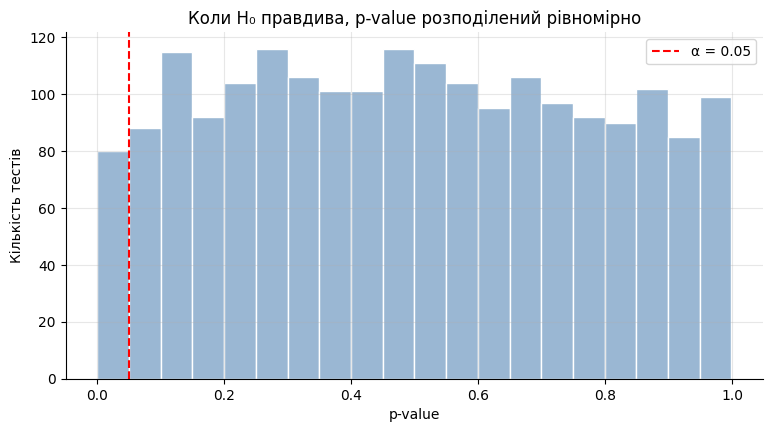

In [26]:
p_values = []
for _ in range(2000):
    a = rng.normal(100, 15, 50)
    b = rng.normal(100, 15, 50)          # та сама генеральна сукупність!
    p_values.append(stats.ttest_ind(a, b, equal_var=False).pvalue)
p_values = np.array(p_values)

print(f'Частка «значущих» результатів, хоча ефекту немає: {(p_values <= 0.05).mean():.1%}')
print(f'Ймовірність хоча б однієї хибної тривоги з 20 тестів: {1 - 0.95 ** 20:.0%}')

plt.hist(p_values, bins=20, color='#9ab7d3', edgecolor='white')
plt.axvline(0.05, color='red', linestyle='--', label='α = 0.05')
plt.title('Коли H₀ правдива, p-value розподілений рівномірно')
plt.xlabel('p-value')
plt.ylabel('Кількість тестів')
plt.legend()
plt.show()

Приблизно 5% A/A-тестів показали «значущу різницю» там, де її **немає**. Що більше тестів, то більше таких «відкриттів».

**Як захиститися:** заздалегідь обирати одну головну метрику; для багатьох тестів — жорсткіший поріг (наприклад, **поправка Бонферроні**: α / кількість тестів).

### Як писати висновок

❌ «p = 0.02, тому нова кнопка краща з ймовірністю 98%.»

✅ «Конверсія в групі B вища на 2.25 п.п. (95% ДІ: від 0.3 до 4.2 п.п.), p = 0.02. При α = 0.05 відхиляємо гіпотезу про однакові конверсії. Ефект, найімовірніше, справжній, але його розмір ще невизначений.»

---
## 13. 🧾 Підсумок: який тест обрати (⏱ 2 хв)

| Питання | Дані | Тест у SciPy |
|---|---|---|
| Середнє = заданому числу? | числові, 1 група | `stats.ttest_1samp(x, popmean)` |
| Середні двох груп різні? | числові, 2 незалежні групи | `stats.ttest_ind(a, b, equal_var=False)` |
| Змінилось «до → після»? | числові, ті самі об'єкти | `stats.ttest_rel(before, after)` |
| Дві категоріальні ознаки пов'язані? | частоти в таблиці | `stats.chi2_contingency(table)` |
| Частоти відповідають очікуваним? | частоти категорій | `stats.chisquare(observed, expected)` |
| Конверсії двох груп різні? | частки (купив/не купив) | z-тест вручну або `chi2_contingency` |
| Частка = заданій? | кількість успіхів з n | `stats.binomtest(k, n, p)` |
| Дві числові змінні пов'язані? | пари чисел | `stats.pearsonr(x, y)` / `stats.spearmanr(x, y)` |

### 5 речей, які варто запам'ятати

1. **H₀ — «ефекту немає».** Ми або відхиляємо її, або ні; «довести H₀» не можна.
2. **p-value — ймовірність даних за умови H₀**, а не ймовірність, що H₀ правдива.
3. **Завжди повідомляйте розмір ефекту і ДІ**, а не лише p-value.
4. **Тест обирають за типом даних:** середні → t-тест, частоти → хі-квадрат, зв'язок числових змінних → кореляція.
5. **Багато тестів = багато хибних «відкриттів».** Плануйте аналіз заздалегідь.

---
## ✍️ Перевірте себе (домашнє завдання)

Під кожним завданням — порожня клітинка для коду.

**Завдання 1.** Монетку підкинули 200 разів, випало 115 орлів. Сформулюйте H₀ і H₁, порахуйте p-value через `stats.binomtest` і зробіть висновок при α = 0.05.

In [27]:
from scipy import stats

# H0: монетка чесна (ймовірність орла = 0.5)
# H1: монетка нечесна (ймовірність орла != 0.5)

# Перевіряємо гіпотезу
result = stats.binomtest(115, n=200, p=0.5)

# Виводимо p-value
print(result.pvalue)

# Висновок:
# p-value = 0.040 < 0.05.
# Відхиляємо нульову гіпотезу H0.
# Є статистично значущі підстави вважати,
# що ймовірність випадіння орла відрізняється від 0.5.

0.040037191613399414


**Завдання 2.** A/B-тест розсилки: лист A відкрили 380 з 2500 отримувачів, лист B — 430 з 2500. Перевірте, чи відрізняються частки відкриттів (z-тест або `chi2_contingency`), і порахуйте 95% ДІ для різниці.

In [28]:
# Кількість отримувачів та відкриттів
n_a = 2500
k_a = 380

n_b = 2500
k_b = 430

# Обчислюємо частки відкриттів
p_a = k_a / n_a
p_b = k_b / n_b

# Виводимо результати у відсотках
print(f"Лист A: {p_a:.2%}")
print(f"Лист B: {p_b:.2%}")

# Проміжний висновок:
# Лист A відкрили 15.2% отримувачів, лист B — 17.2%.
# Лист B має вищу частку відкриттів на 2 відсоткові пункти.
# Щоб визначити, чи є ця різниця статистично значущою,
# потрібно провести статистичний тест.

# H0: частки відкриттів листів A і B однакові
# H1: частки відкриттів листів A і B відрізняються

# Створюємо таблицю: відкрили / не відкрили
table = [
    [k_a, n_a - k_a],
    [k_b, n_b - k_b]
]

# Виконуємо статистичний тест
test_result = stats.chi2_contingency(table, correction=False)

# Виводимо p-value
print(f"p-value = {test_result.pvalue:.4f}")

# Висновок:
# p-value = 0.0550 > 0.05.
# Немає достатніх підстав відхилити H0.
# Лист B має вищу частку відкриттів на 2 відсоткові пункти,
# але різниця не є статистично значущою при alpha = 0.05.

import numpy as np

# Різниця між частками відкриттів
diff = p_b - p_a

# Стандартна похибка різниці
se_diff = np.sqrt(
    p_a * (1 - p_a) / n_a +
    p_b * (1 - p_b) / n_b
)

# Межі 95% довірчого інтервалу
ci_low = diff - 1.96 * se_diff
ci_high = diff + 1.96 * se_diff

# Виводимо результат
print(f"95% ДІ: від {ci_low:+.2%} до {ci_high:+.2%}")

# Остаточний висновок:
# Лист A: 15.2%, лист B: 17.2%.
# Різниця становить 2 відсоткові пункти.
# p-value = 0.0550 > 0.05, тому H0 не відхиляємо.
# 95% ДІ: від -0.04 до +4.04 відсоткового пункту.
# Інтервал містить 0.
# Статистично значущої різниці між листами
# на рівні alpha = 0.05 не виявлено.

Лист A: 15.20%
Лист B: 17.20%
p-value = 0.0550
95% ДІ: від -0.04% до +4.04%


**Завдання 3.** Для вибірки `check_a` (середній чек на лендингу A) побудуйте 95% довірчий інтервал для середнього через `stats.t.interval`. Перевірте гіпотезу, що середній чек дорівнює 500 грн.

In [29]:
# H0: середній чек дорівнює 500 грн
# H1: середній чек не дорівнює 500 грн

# Перевіряємо кількість чеків
print("Кількість чеків:", len(check_a))

# Обчислюємо середній чек
print(f"Середній чек: {check_a.mean():.2f} грн")

# Обчислюємо 95% довірчий інтервал
ci = stats.t.interval(
    confidence=0.95,
    df=len(check_a) - 1,
    loc=check_a.mean(),
    scale=stats.sem(check_a)
)

# Виводимо результат
print(f"95% ДІ: від {ci[0]:.2f} до {ci[1]:.2f} грн")

# Перевіряємо гіпотезу, що середній чек = 500 грн
test_result = stats.ttest_1samp(check_a, popmean=500)

# Виводимо p-value
print(f"p-value = {test_result.pvalue:.4f}")

# Остаточний висновок:
# Значення 500 грн входить у 95% довірчий інтервал.
# Оскільки p-value > 0.05, нульову гіпотезу не відхиляємо.
# Немає достатніх статистичних підстав стверджувати,
# що середній чек відрізняється від 500 грн.

Кількість чеків: 60
Середній чек: 507.00 грн
95% ДІ: від 480.56 до 533.44 грн
p-value = 0.5982


**Завдання 4.** Таблиця «тариф × продовжив підписку»: Базовий — 300 продовжили, 700 ні; Преміум — 180 продовжили, 220 ні. Чи пов'язаний тариф з продовженням? Порахуйте частки продовження для кожного тарифу і зробіть висновок.

In [30]:
import pandas as pd

# H0: тариф і продовження підписки не пов'язані
# H1: тариф і продовження підписки пов'язані

# Створюємо таблицю з даними
table = pd.DataFrame({
    'Продовжив': [300, 180],
    'Не продовжив': [700, 220]
}, index=['Базовий', 'Преміум'])

# Обчислюємо частки продовження підписки
rates = table['Продовжив'] / table.sum(axis=1)

# Виводимо результати у відсотках
print((rates * 100).round(2))

# Проміжний висновок:
# Базовий тариф: 30% клієнтів продовжили підписку.
# Преміум тариф: 45% клієнтів продовжили підписку.
# Різниця становить 15 відсоткових пунктів.
# Для перевірки статистичної значущості зв'язку
# між тарифом і продовженням підписки потрібен тест хі-квадрат.

# Перевіряємо зв'язок між тарифом і продовженням підписки
chi2, p_value, dof, expected = stats.chi2_contingency(table)

# Виводимо результат тесту
print(f"Хі-квадрат = {chi2:.4f}")

# print(f"p-value = {p_value:.4f}")

print(f"p-value = {p_value:.2e}")

# Остаточний висновок:
# Базовий тариф: 30% продовжень.
# Преміум тариф: 45% продовжень.
# Різниця становить 15 відсоткових пунктів.
# Хі-квадрат = 27.8707.
# p-value < 0.05, тому відхиляємо H0.
# Між типом тарифу та продовженням підписки
# існує статистично значущий зв'язок.
# Клієнти Преміум-тарифу частіше продовжують підписку.


Базовий   30.0000
Преміум   45.0000
dtype: float64
Хі-квадрат = 27.8707
p-value = 1.30e-07


---
## 🔑 Розв'язки (для викладача)

In [31]:
# Завдання 1. H₀: p = 0.5 (монетка чесна); H₁: p ≠ 0.5
res = stats.binomtest(115, n=200, p=0.5)
print(f'p-value = {res.pvalue:.4f} →', 'відхиляємо H₀' if res.pvalue <= 0.05 else 'не відхиляємо H₀')

p-value = 0.0400 → відхиляємо H₀


In [32]:
# Завдання 2
na, ka, nb, kb = 2500, 380, 2500, 430
pa, pb = ka / na, kb / nb
pp = (ka + kb) / (na + nb)
z2 = (pb - pa) / np.sqrt(pp * (1 - pp) * (1 / na + 1 / nb))
p2 = 2 * stats.norm.sf(abs(z2))
se2 = np.sqrt(pa * (1 - pa) / na + pb * (1 - pb) / nb)
print(f'A: {pa:.2%}, B: {pb:.2%}, різниця {pb - pa:+.2%}, p = {p2:.4f}')
print(f'95% ДІ: {pb - pa - 1.96 * se2:+.2%} … {pb - pa + 1.96 * se2:+.2%}')

A: 15.20%, B: 17.20%, різниця +2.00%, p = 0.0550
95% ДІ: -0.04% … +4.04%


In [33]:
# Завдання 3
ci = stats.t.interval(0.95, df=len(check_a) - 1, loc=check_a.mean(), scale=stats.sem(check_a))
print(f'95% ДІ: {ci[0]:.1f} … {ci[1]:.1f} грн')
res = stats.ttest_1samp(check_a, popmean=500)
print(f't = {res.statistic:.2f}, p = {res.pvalue:.4f}')

95% ДІ: 480.6 … 533.4 грн
t = 0.53, p = 0.5982


In [34]:
# Завдання 4
t4 = pd.DataFrame({'Продовжив': [300, 180], 'Ні': [700, 220]}, index=['Базовий', 'Преміум'])
print((t4['Продовжив'] / t4.sum(axis=1)).round(3))
chi2, p, dof, exp = stats.chi2_contingency(t4)
print(f'χ² = {chi2:.2f}, p = {p:.6f} → тариф пов\'язаний з продовженням')

Базовий   0.3000
Преміум   0.4500
dtype: float64
χ² = 27.87, p = 0.000000 → тариф пов'язаний з продовженням
